ANFIS TEMPERATURE PREDICTION
-----------------------------------
Training samples: 100
Number of fuzzy rules: 4
Mean Squared Error: 0.0
Root Mean Squared Error: 0.0
Mean Absolute Error: 0.0

Sample Input:
Humidity: 60.0 %
Previous Temperature: 30.0 C
Predicted Temperature: 30.67 C


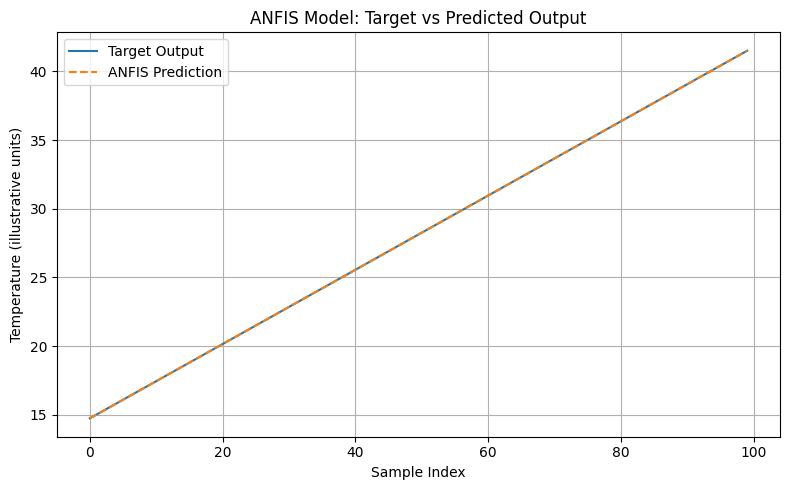

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ANFIS: Adaptive Neuro-Fuzzy Inference System
# Case Study: Temperature Prediction

np.random.seed(42)

# Step 1: Generate sample training data
humidity = np.linspace(20, 90, 100)
previous_temp = np.linspace(15, 40, 100)

X = np.column_stack((humidity, previous_temp))

# Illustrative target relationship (synthetic data)
y = 0.15 * humidity + 0.65 * previous_temp + 2

# Step 2: Define Gaussian membership functions
centers = np.array([
    [20, 15], [20, 40],
    [90, 15], [90, 40]
], dtype=float)

sigmas = np.array([25.0, 10.0])

def membership(x, center, sigma):
    return np.exp(-((x - center) ** 2) / (2 * sigma
** 2))

# Step 3: Calculate normalized rule firing strengths
def get_strengths(X):
    strengths = []

    for c in centers:
        mu1 = membership(X[:, 0], c[0], sigmas[0])
        mu2 = membership(X[:, 1], c[1], sigmas[1])
        strengths.append(mu1 * mu2)
    strengths = np.array(strengths).T
    return strengths / (strengths.sum(axis=1,
keepdims=True) + 1e-10)

# Step 4: Train Sugeno consequent parameters
# Each rule has the form:
# f_i = p_i * humidity + q_i * previous_temp + r_i

def design_matrix(X, strengths):
    blocks = []

    for i in range(strengths.shape[1]):
        w = strengths[:, i:i+1]
        blocks.append(w * X[:, 0:1])
        blocks.append(w * X[:, 1:2])
        blocks.append(w)

    return np.hstack(blocks)

strengths = get_strengths(X)
A = design_matrix(X, strengths)

# Least-squares estimation of consequent parameters
theta, _, _, _ = np.linalg.lstsq(A, y, rcond=None)

# Step 5: Predict output
def predict(X):
    strengths = get_strengths(X)
    A = design_matrix(X, strengths)
    return A @ theta

predicted = predict(X)

# Step 6: Evaluate model
mse = np.mean((y - predicted) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(y - predicted))

print("ANFIS TEMPERATURE PREDICTION")
print("-" * 35)
print("Training samples:", len(X))
print("Number of fuzzy rules:", len(centers))
print("Mean Squared Error:", round(mse, 4))
print("Root Mean Squared Error:", round(rmse,
4))
print("Mean Absolute Error:", round(mae, 4))

# Step 7: Predict for a sample input
sample = np.array([[60, 30]], dtype=float)
result = predict(sample)[0]

print("\nSample Input:")
print("Humidity:", sample[0, 0], "%")
print("Previous Temperature:", sample[0, 1], "C")



print("Predicted Temperature:", round(result, 2),
"C")

# Step 8: Plot actual and predicted outputs
plt.figure(figsize=(8, 5))
plt.plot(y, label="Target Output")
plt.plot(predicted, "--", label="ANFIS Prediction")
plt.xlabel("Sample Index")
plt.ylabel("Temperature (illustrative units)")
plt.title("ANFIS Model: Target vs Predicted Output")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()